# Climate-Sensitive Death Prediction

Goal: predict whether a death is climate-sensitive (`is_climate_sensitive`) from demographics, location, weather and satellite climate features.

Metric: `0.6 * F1 + 0.4 * ROC-AUC`

Workflow:
1. Load and merge the data
2. Clean and engineer features with one shared function
3. Explore the key patterns
4. Build one scikit-learn `Pipeline` (impute, scale, encode, model)
5. Evaluate, tune the decision threshold, check feature importance
6. Refit on all labelled data and write the submission

In [6]:
# 📚 Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 200)

In [7]:
# Settings
TARGET = "is_climate_sensitive"
SEED = 42

## 1. Load and merge the data

`climate_features.csv` holds extra climate columns per `ID`. Merge them into Train and Test. `deathdate` already exists in both files, so drop the duplicate copy first.

In [8]:
climate = pd.read_csv("climate_features.csv").drop(columns=["deathdate"])

train = pd.read_csv("Train.csv").merge(climate, on="ID", how="left")
test = pd.read_csv("Test.csv").merge(climate, on="ID", how="left")

# Remove duplicate rows (ignoring ID) from the training data
train = train.drop_duplicates(subset=[c for c in train.columns if c != "ID"])

print("Train:", train.shape, "| missing:", train.isna().sum().sum())
print("Test: ", test.shape, "| missing:", test.isna().sum().sum())
train.sample(5)

Train: (3144, 29) | missing: 0
Test:  (1030, 28) | missing: 0


,ID,zone,gender,deathdate,age,avg_temperature,max_temperature,min_temperature,precipitation,latitude,longitude,location,is_climate_sensitive,elevation,hot_days_30d,max_daily_rain_30d,ndvi_30d,ndvi_90d,rain_days_30d,rain_sum_30d,rain_sum_7d,rain_sum_90d,slope,tavg_30d,tavg_7d,tavg_90d,temp_range_mean_30d,tmax_30d,tmin_30d
80,ID_052EE082,Rural,Male,2008-12-07,0.0,22.606436,27.024134,18.190495,0.028328,0.574287,33.538210,"Wairama, Iganga, Uganda",1,1122,0,16.955997,0.70420,0.74525,7,57.492504,0.000000,347.794208,0.356825,21.817780,22.037904,21.689734,7.640690,28.235101,16.924661
2309,ID_4B06CFDD,Rural,Female,2016-12-18,52.0,23.220974,28.062765,18.544325,0.016014,0.547201,33.488916,"Nawanzu, Iganga, Uganda",0,1145,0,25.538670,0.62910,0.62910,13,119.939318,5.281223,341.073911,0.299996,22.468805,22.830375,22.608006,7.988299,28.100687,16.876718
1795,ID_B3BCA915,Peri_urban,Female,2014-05-07,33.0,21.802293,24.383297,19.111904,4.036163,0.608396,33.482668,"Brac Uganda Iganga Regional Branch, Bikadho Ro...",1,1132,0,18.338060,0.53425,0.45080,16,128.091362,38.530230,373.724349,0.166667,22.306631,22.780557,23.193133,7.121780,27.695825,18.336740
474,ID_9DCB8F62,Rural,Female,2009-08-24,0.0,21.344500,25.166864,19.008455,2.794475,0.552776,33.511188,"Bukwaya, Iganga, Uganda",1,1122,0,14.647542,0.63125,0.66050,8,60.239190,35.204345,161.172285,0.356825,21.880623,21.706138,21.581978,8.088714,27.759775,17.539194
2689,ID_41686F47,Peri_urban,Female,2020-05-03,15.0,20.568532,22.582416,19.146470,1.683066,0.608396,33.482668,"Brac Uganda Iganga Regional Branch, Bikadho Ro...",1,1132,0,22.701330,0.51700,0.52450,21,258.475600,59.754838,581.445372,0.166667,22.360187,21.972487,22.767077,6.295848,28.746179,18.106485


## 2. Cleaning and feature engineering

One function prepares both Train and Test. This keeps the two datasets identical in structure and removes the copy-pasted test code from the original notebook.

- **Location**: fix typos, normalise spacing and casing, then extract the `region` (the segment before ", Uganda").
- **Date**: year, month and Uganda's rainy seasons (March to May, September to November).
- **Rainfall**: log precipitation, intensity and recent-vs-longer-term ratios.
- **Temperature**: daily range and short-term anomalies.
- **Vegetation**: NDVI change (drought or crop stress signal).
- **Age**: infant, under-5 and elderly flags, plus an under-5 × rainfall interaction.

In [9]:
RAINY_MONTHS = [3, 4, 5, 9, 10, 11]


def clean_location(s):
    return (
        s.str.replace("Propeer", "Proper", regex=False)
         .str.replace("Buwoya", "Buwaya", regex=False)
         .str.replace(", Eastern Region", "", regex=False)
         .str.replace(r",\s*,", ",", regex=True)
         .str.replace(r"\s+", " ", regex=True)
         .str.strip()
         .str.replace(r"\s*,\s*", ", ", regex=True)
         .str.title()
    )


def prepare(df):
    df = df.copy()

    # Location -> region
    df["location"] = clean_location(df["location"])
    df["region"] = df["location"].str.split(",").str[-2].str.strip()

    # Date
    date = pd.to_datetime(df["deathdate"])
    df["death_year"] = date.dt.year
    df["death_month"] = date.dt.month
    df["is_rainy_season"] = df["death_month"].isin(RAINY_MONTHS).astype(int)

    # Rainfall
    df["log_precipitation"] = np.log1p(df["precipitation"])
    df["rain_intensity_30d"] = df["rain_sum_30d"] / (df["rain_days_30d"] + 1)
    df["rain_recent_ratio"] = df["rain_sum_7d"] / (df["rain_sum_30d"] + 1)
    df["rain_30d_vs_90d"] = df["rain_sum_30d"] / (df["rain_sum_90d"] + 1)

    # Temperature
    df["temp_range"] = df["max_temperature"] - df["min_temperature"]
    df["temp_anomaly_7d"] = df["tavg_7d"] - df["tavg_90d"]
    df["heat_stress_30d"] = df["tmax_30d"] - df["tavg_90d"]

    # Vegetation
    df["ndvi_change"] = df["ndvi_30d"] - df["ndvi_90d"]

    # Age
    df["is_infant"] = (df["age"] == 0).astype(int)
    df["is_under5"] = (df["age"] < 5).astype(int)
    df["is_elderly"] = (df["age"] >= 60).astype(int)
    df["under5_x_rain30"] = df["is_under5"] * df["rain_sum_30d"]

    return df


train = prepare(train)
test = prepare(test)

train[["location", "region", "death_year", "death_month", "is_under5"]].head()

,location,region,death_year,death_month,is_under5
0,"Izimba, Iganga, Uganda",Iganga,2007,10,0
1,"Nawanzu, Iganga, Uganda",Iganga,2008,1,1
2,"Buluza, Iganga, Uganda",Iganga,2008,2,0
3,"Nawanzu, Iganga, Uganda",Iganga,2008,2,1
4,"Magada, Mbale City, Bugisa Sub-Region, Uganda",Bugisa Sub-Region,2008,2,0


## 3. Exploratory data analysis

Four views of the target: overall balance, and the climate-sensitive rate by age group, region and year.

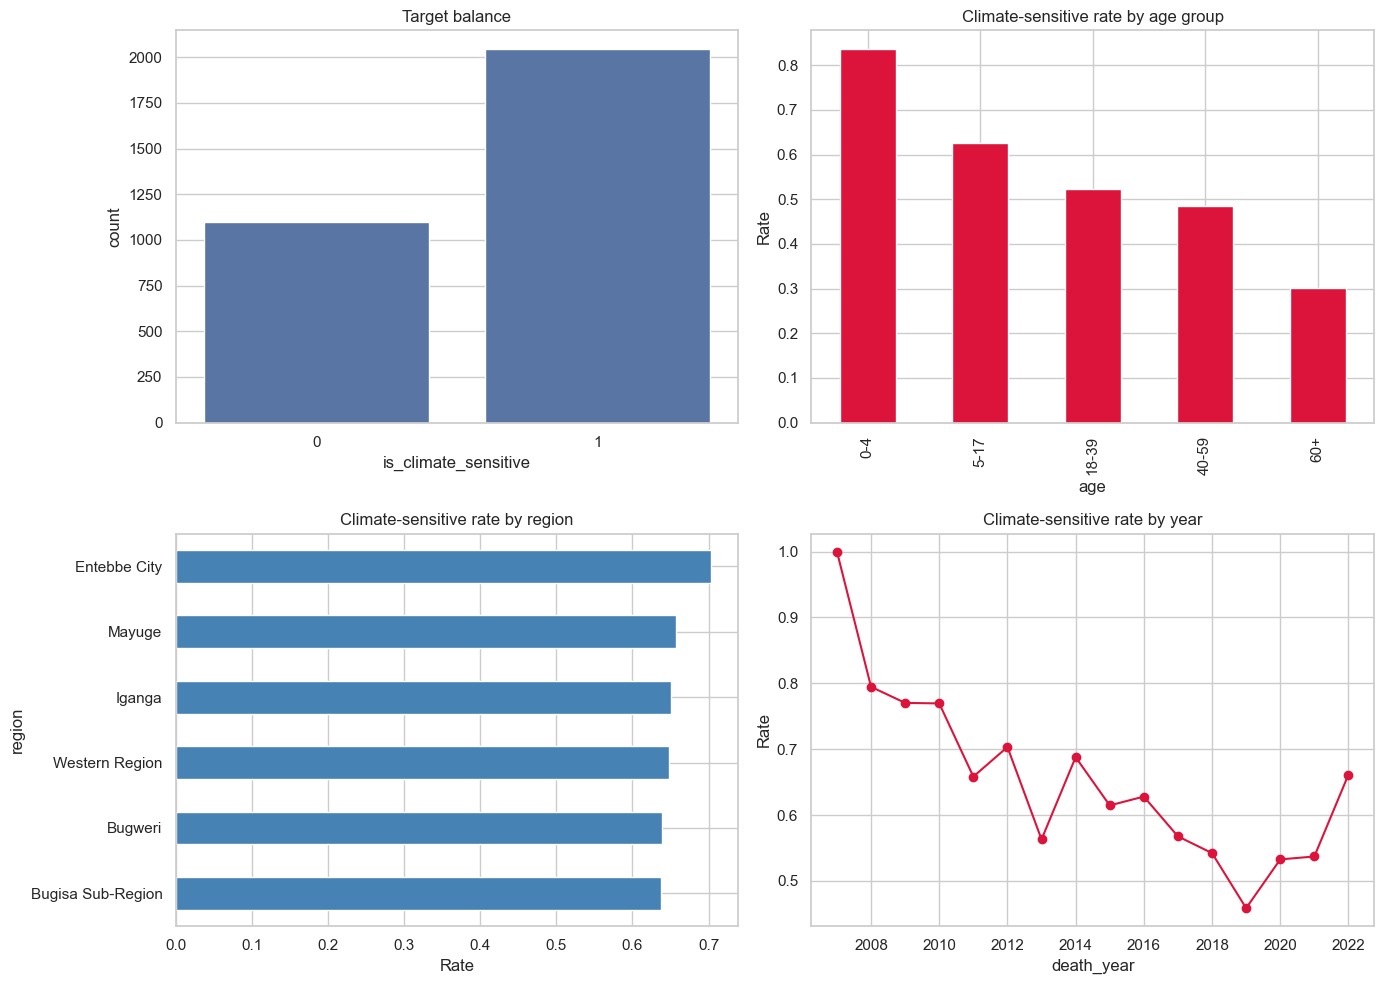

In [10]:
age_group = pd.cut(
    train["age"],
    bins=[-1, 4, 17, 39, 59, np.inf],
    labels=["0-4", "5-17", "18-39", "40-59", "60+"],
)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(x=TARGET, data=train, ax=axes[0, 0])
axes[0, 0].set_title("Target balance")

train.groupby(age_group, observed=True)[TARGET].mean().plot(
    kind="bar", ax=axes[0, 1], color="crimson"
)
axes[0, 1].set_title("Climate-sensitive rate by age group")
axes[0, 1].set_ylabel("Rate")

train.groupby("region")[TARGET].mean().sort_values().plot(
    kind="barh", ax=axes[1, 0], color="steelblue"
)
axes[1, 0].set_title("Climate-sensitive rate by region")
axes[1, 0].set_xlabel("Rate")

train.groupby("death_year")[TARGET].mean().plot(
    marker="o", ax=axes[1, 1], color="crimson"
)
axes[1, 1].set_title("Climate-sensitive rate by year")
axes[1, 1].set_ylabel("Rate")

plt.tight_layout()
plt.show()

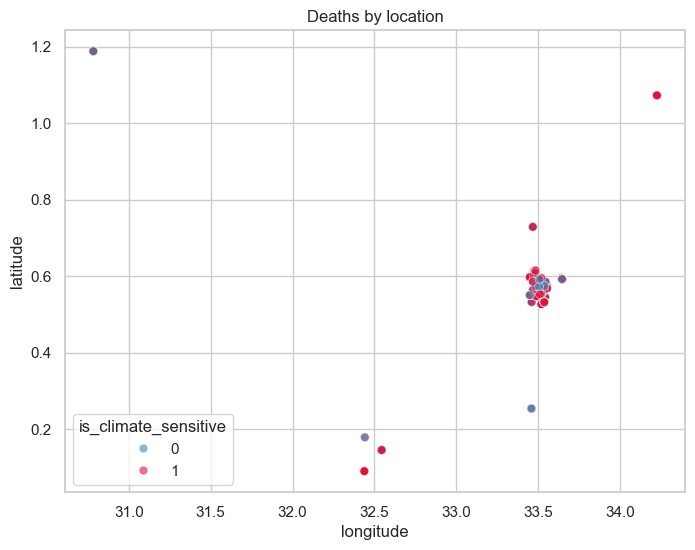

In [11]:
# Where the deaths happened, coloured by target
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=train, x="longitude", y="latitude", hue=TARGET,
    palette={0: "steelblue", 1: "crimson"}, alpha=0.6, s=40,
)
plt.title("Deaths by location")
plt.show()

## 4. Features and preprocessing pipeline

- **Dropped**: `ID`, `deathdate` (replaced by year and month), `location` (near-unique free text, replaced by `region`) and `hot_days_30d` (constant, carries no signal).
- **Numeric**: median imputation, then standard scaling (unnecessary for Random Forest, kept so the pipeline works unchanged if the classifier is swapped back).
- **Categorical**: most-frequent imputation, then one-hot encoding. `handle_unknown="ignore"` covers regions seen only in Test.

The pipeline fits all preprocessing on training data only, so no information leaks from validation or test rows.

In [12]:
DROP_COLS = ["ID", "deathdate", "location", "hot_days_30d", TARGET]
CAT_COLS = ["gender", "zone", "region"]

X = train.drop(columns=DROP_COLS)
y = train[TARGET]
NUM_COLS = [c for c in X.columns if c not in CAT_COLS]

print(f"{len(NUM_COLS)} numeric + {len(CAT_COLS)} categorical features")
print("Target balance:", y.value_counts(normalize=True).round(3).to_dict())

37 numeric + 3 categorical features
Target balance: {1: 0.65, 0: 0.35}


In [13]:
numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore")),
])

preprocess = ColumnTransformer([
    ("num", numeric_pipe, NUM_COLS),
    ("cat", categorical_pipe, CAT_COLS),
])

model = Pipeline([
    ("preprocess", preprocess),
    ("clf", RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1
    )),
])

model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocess', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contai

## 5. Train and evaluate

80/20 stratified split. `evaluate()` prints F1, ROC-AUC, the combined competition score, a classification report and a confusion matrix.

Validation (threshold = 0.50)
  F1:               0.8014
  ROC-AUC:          0.8034
  Combined (60/40): 0.8022

              precision    recall  f1-score   support

           0       0.64      0.54      0.58       220
           1       0.77      0.83      0.80       409

    accuracy                           0.73       629
   macro avg       0.70      0.69      0.69       629
weighted avg       0.72      0.73      0.73       629



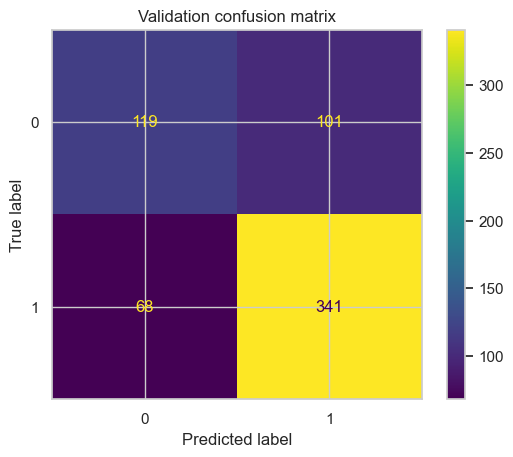

In [14]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

model.fit(X_train, y_train)
val_proba = model.predict_proba(X_val)[:, 1]


def evaluate(y_true, proba, threshold=0.5, title="Validation"):
    pred = (proba >= threshold).astype(int)
    f1 = f1_score(y_true, pred)
    auc = roc_auc_score(y_true, proba)
    print(f"{title} (threshold = {threshold:.2f})")
    print(f"  F1:               {f1:.4f}")
    print(f"  ROC-AUC:          {auc:.4f}")
    print(f"  Combined (60/40): {0.6 * f1 + 0.4 * auc:.4f}\n")
    print(classification_report(y_true, pred))
    ConfusionMatrixDisplay(confusion_matrix(y_true, pred)).plot()
    plt.title(f"{title} confusion matrix")
    plt.show()


evaluate(y_val, val_proba)

### Tune the decision threshold

`class_weight="balanced"` pushes predictions toward the minority class, so 0.5 is rarely the best cut-off for F1. ROC-AUC ignores the threshold, so tuning the threshold only moves the F1 part of the score.

The threshold comes from the validation set. Treat the tuned score as slightly optimistic.

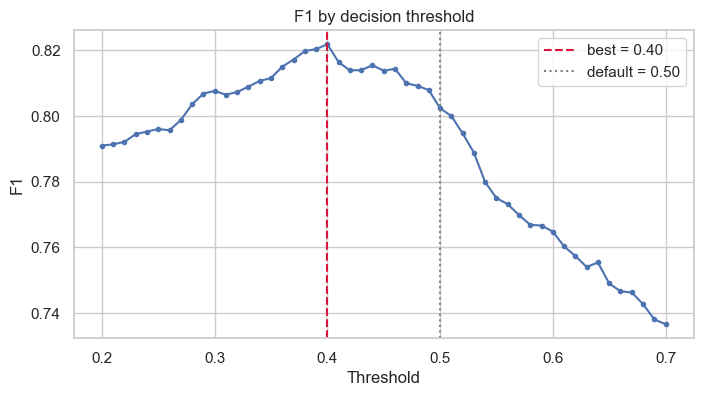

Validation, tuned (threshold = 0.40)
  F1:               0.8219
  ROC-AUC:          0.8034
  Combined (60/40): 0.8145

              precision    recall  f1-score   support

           0       0.75      0.36      0.49       220
           1       0.73      0.94      0.82       409

    accuracy                           0.74       629
   macro avg       0.74      0.65      0.66       629
weighted avg       0.74      0.74      0.71       629



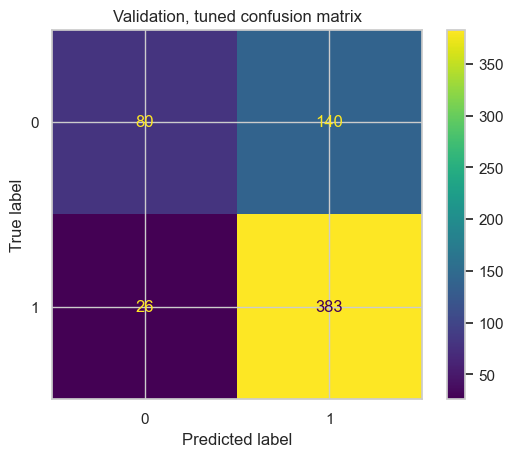

In [15]:
thresholds = np.arange(0.20, 0.71, 0.01)
f1_scores = [f1_score(y_val, (val_proba >= t).astype(int)) for t in thresholds]
best_threshold = thresholds[int(np.argmax(f1_scores))]

plt.figure(figsize=(8, 4))
plt.plot(thresholds, f1_scores, marker=".")
plt.axvline(best_threshold, color="crimson", linestyle="--", label=f"best = {best_threshold:.2f}")
plt.axvline(0.5, color="grey", linestyle=":", label="default = 0.50")
plt.xlabel("Threshold")
plt.ylabel("F1")
plt.title("F1 by decision threshold")
plt.legend()
plt.show()

evaluate(y_val, val_proba, threshold=best_threshold, title="Validation, tuned")

## 6. Feature importance

Two views, combined into one ranking:
- **Permutation importance**: shuffles one raw column at a time and measures the drop in validation ROC-AUC. Model-agnostic, but slower and noisier for correlated features.
- **Random Forest importance**: mean decrease in impurity across all trees, free from the fitted model. Biased toward high-cardinality features, and correlated features can split importance between them.

Each categorical column's one-hot dummies are summed back into a single score so it lines up with the raw column used by permutation importance. Both scores are scaled to 0-1 by their own max and averaged into a `combined_score`, so neither method dominates just because it happens to produce larger numbers.

In [ ]:
# Permutation importance (raw columns, drop in ROC-AUC)
perm = permutation_importance(
    model, X_val, y_val,
    scoring="roc_auc", n_repeats=10, random_state=SEED, n_jobs=-1,
)
perm_importance = pd.DataFrame({
    "feature": X_val.columns,
    "perm_importance": perm.importances_mean,
})

# Random Forest importance (mean decrease in impurity), summed back from
# one-hot dummies to the raw categorical column so it lines up with perm_importance
def base_feature(name):
    name = name.split("__", 1)[1]
    for c in CAT_COLS:
        if name.startswith(c + "_"):
            return c
    return name

feature_names = model.named_steps["preprocess"].get_feature_names_out()
rf_raw = pd.DataFrame({
    "feature": [base_feature(f) for f in feature_names],
    "importance": model.named_steps["clf"].feature_importances_,
})
rf_importance = rf_raw.groupby("feature", as_index=False)["importance"].sum()
rf_importance.columns = ["feature", "rf_importance"]

# Combine: scale each method 0-1 by its own max, then average
importance = perm_importance.merge(rf_importance, on="feature", how="outer").fillna(0)
importance["perm_norm"] = importance["perm_importance"] / importance["perm_importance"].max()
importance["rf_norm"] = importance["rf_importance"] / importance["rf_importance"].max()
importance["combined_score"] = (importance["perm_norm"] + importance["rf_norm"]) / 2
importance = importance.sort_values("combined_score", ascending=False).reset_index(drop=True)

top = importance.head(15).iloc[::-1]
plt.figure(figsize=(10, 6))
plt.barh(top["feature"], top["perm_norm"], color="steelblue", alpha=0.7, label="Permutation (norm)")
plt.barh(top["feature"], top["rf_norm"], color="seagreen", alpha=0.5, label="Random Forest (norm)")
plt.xlabel("Normalized importance")
plt.title("Top 15 features (combined ranking)")
plt.legend()
plt.tight_layout()
plt.show()

importance.head(15)

## 6b. Reduce to the top features

Take the top 15 features by `combined_score` and look at their correlation matrix. Highly correlated pairs (|r| >= 0.85) carry mostly redundant signal — for a Random Forest that's split budget wasted on near-duplicates. Within each such pair, keep whichever feature ranks higher on `combined_score` and drop the other, then rebuild `X`/`y` on this smaller, cleaner set.

In [ ]:
TOP_N = 15
CORR_THRESHOLD = 0.85

top_features = importance.head(TOP_N)["feature"].tolist()
numeric_top = [f for f in top_features if f in NUM_COLS]
categorical_top = [f for f in top_features if f in CAT_COLS]

corr = train[numeric_top].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation matrix — top 15 numeric features")
plt.tight_layout()
plt.show()

# Within each highly-correlated pair, drop whichever ranks lower on combined_score
score_by_feature = importance.set_index("feature")["combined_score"]
to_drop = set()
for i, f1 in enumerate(numeric_top):
    for f2 in numeric_top[i + 1:]:
        if f1 in to_drop or f2 in to_drop:
            continue
        if abs(corr.loc[f1, f2]) >= CORR_THRESHOLD:
            to_drop.add(f1 if score_by_feature[f1] < score_by_feature[f2] else f2)

FINAL_FEATURES = [f for f in top_features if f not in to_drop]
print(f"Dropped {len(to_drop)} redundant feature(s): {sorted(to_drop)}")
print(f"Final feature set ({len(FINAL_FEATURES)}): {FINAL_FEATURES}")

In [ ]:
# Rebuild X and y on the reduced, cleaner feature set
CAT_COLS = [c for c in FINAL_FEATURES if c in categorical_top]
NUM_COLS = [c for c in FINAL_FEATURES if c not in CAT_COLS]

X = train[FINAL_FEATURES]
y = train[TARGET]

print(f"{len(NUM_COLS)} numeric + {len(CAT_COLS)} categorical features")
X.head()

### Retrain on the reduced feature set

Same pipeline shape, fewer and less redundant columns. New split, so the numbers below aren't directly comparable to the full-feature run above, but they show whether the pruned set holds up.

In [ ]:
numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore")),
])

preprocess = ColumnTransformer([
    ("num", numeric_pipe, NUM_COLS),
    ("cat", categorical_pipe, CAT_COLS),
])

model = Pipeline([
    ("preprocess", preprocess),
    ("clf", RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1
    )),
])

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

model.fit(X_train, y_train)
val_proba = model.predict_proba(X_val)[:, 1]

evaluate(y_val, val_proba, title="Validation, reduced features")

In [ ]:
thresholds = np.arange(0.20, 0.71, 0.01)
f1_scores = [f1_score(y_val, (val_proba >= t).astype(int)) for t in thresholds]
best_threshold = thresholds[int(np.argmax(f1_scores))]

plt.figure(figsize=(8, 4))
plt.plot(thresholds, f1_scores, marker=".")
plt.axvline(best_threshold, color="crimson", linestyle="--", label=f"best = {best_threshold:.2f}")
plt.axvline(0.5, color="grey", linestyle=":", label="default = 0.50")
plt.xlabel("Threshold")
plt.ylabel("F1")
plt.title("F1 by decision threshold (reduced feature set)")
plt.legend()
plt.show()

evaluate(y_val, val_proba, threshold=best_threshold, title="Validation, tuned, reduced features")

## 7. Final model and submission

Refit the same pipeline (now on the reduced feature set from section 6b) on all labelled data, predict Test, and apply the tuned threshold.

- `TargetF1`: 0/1 prediction
- `TargetRAUC`: predicted probability

In [ ]:
model.fit(X, y)

X_test = test[X.columns]
test_proba = model.predict_proba(X_test)[:, 1]

submission = pd.DataFrame({
    "ID": test["ID"],
    "TargetF1": (test_proba >= best_threshold).astype(int),
    "TargetRAUC": test_proba,
})
submission.to_csv("submission.csv", index=False)

print(submission.shape, "| predicted climate-sensitive rate:", submission["TargetF1"].mean().round(3))
submission.head()